# Ранжирование товаров в поисковой выдаче



In [1]:
import gc
import re
from collections import Counter

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics import ndcg_score

## 1. Данные

Три таблицы: `train.csv` с метками, `test.csv` без меток и справочник `products.csv` с карточками товаров. 

In [ ]:
event_types = {
    'search_number': 'int32', 'query': 'category', 'device': 'category',
    'product_id': 'int32', 'product_position': 'int16', 'relevance': 'int8',
    'response_products': 'int32', 'response_time': 'int32', 'browse_time': 'int32',
    'filters_applied': 'int16', 'available': 'int8', 'price': 'int32',
    'price_discount': 'int32', 'price_is_super': 'int8', 'price_is_discounted': 'int8',
    'selected_category_id': 'int32', 'user_number': 'int32',
}
events = pd.read_csv('/kaggle/input/21-vek-by-searched-products-ranking/train.csv', dtype=event_types, parse_dates=['date'])
events.head(10)

,query,date,device,user_number,search_number,product_id,selected_category_id,product_position,response_products,response_time,browse_time,filters_applied,price_is_discounted,price_is_super,price,price_discount,available,relevance
0,bagi,2024-07-03,desktop,119760,1963,6221252,10709,2,9,76,2525,0,0,0,2940,0,2,0
1,bagi,2024-07-03,desktop,119760,1963,6221258,10718,3,3,75,2525,0,0,0,2036,0,2,2
2,bagi,2024-07-03,desktop,119760,1963,6221260,10718,1,3,75,2525,0,0,0,1955,0,2,1
3,bagi,2024-07-03,desktop,119760,1963,6221262,10718,2,3,75,2525,0,0,0,2442,0,2,0
4,bagi,2024-07-03,desktop,119760,1963,6221264,10709,9,9,76,2525,0,0,0,2165,0,2,0
5,bagi,2024-07-03,desktop,119760,1963,6221289,10709,7,9,76,2525,0,0,0,1869,0,2,0
6,bagi,2024-07-03,desktop,119760,1963,7636672,10709,4,9,76,2525,0,0,0,3336,0,2,0
7,bagi,2024-07-03,desktop,119760,1963,7791373,10709,5,9,76,2525,0,0,0,1728,0,2,0
8,bagi,2024-07-03,desktop,119760,1963,7791374,10709,8,9,76,2525,0,0,0,1634,0,2,0
9,bagi,2024-07-03,desktop,119760,1963,7791377,10709,6,9,76,2525,0,0,0,1772,0,2,0


In [ ]:
test = pd.read_csv('/kaggle/input/21-vek-by-searched-products-ranking/test.csv', parse_dates=['date'])
catalog = pd.read_csv('/kaggle/input/21-vek-by-searched-products-ranking/prodcuts.csv')

for name, frame in [('train', events), ('test', test), ('catalog', catalog)]:
    print(f"{name:<8} {frame.shape[0]:>9,} строк  {frame.shape[1]:>3} столбцов  "
          f"пропусков {int(frame.isna().sum().sum()):>6}")

test.head(5)

train    6,559,869 строк   18 столбцов  пропусков      0
test       252,720 строк   18 столбцов  пропусков      0
catalog     36,673 строк   11 столбцов  пропусков      0


,query,date,device,user_number,search_number,product_id,selected_category_id,product_position,response_products,response_time,browse_time,filters_applied,price_is_discounted,price_is_super,price,price_discount,available,session_product_id
0,",tkbpyf",2025-08-27,desktop,8663,308049,8080243,399,1,100,8,911,0,0,0,963,0,2,10_8080243
1,",tkbpyf",2025-08-27,desktop,8663,308049,8826131,399,2,100,8,911,0,0,0,517,0,2,10_8826131
2,",tkbpyf",2025-08-27,desktop,8663,308049,7850512,399,3,100,8,911,0,0,0,598,0,2,10_7850512
3,",tkbpyf",2025-08-27,desktop,8663,308049,5897964,399,4,100,8,911,0,0,0,1196,0,2,10_5897964
4,",tkbpyf",2025-08-27,desktop,8663,308049,6915061,399,5,100,8,911,0,0,0,620,0,2,10_6915061


## 2. просмотр данных

In [4]:
tail_columns = ['price', 'price_discount', 'browse_time', 'response_time',
                'response_products', 'product_position']

print(events[tail_columns].describe(percentiles=[0.5, 0.9, 0.99, 0.999]).round(1).to_string())

print("\nвыше 99-го процентиля:")
for column in tail_columns:
    threshold = events[column].quantile(0.99)
    above = int((events[column] > threshold).sum())
    print(f"  {column:<18} порог {threshold:>9.0f}  строк {above:>8,}  ({above / len(events) * 100:.2f}%)")

           price  price_discount  browse_time  response_time  response_products  product_position
count  6559869.0       6559869.0    6559869.0      6559869.0          6559869.0         6559869.0
mean    102373.3         11153.7       1000.2          178.5               49.5              43.7
std     144410.3         24294.4       1306.6          187.6               32.0              63.6
min          0.0             0.0          0.0            0.0                3.0               1.0
50%      29868.0           313.0        519.0          133.0               30.0              19.0
90%     319900.0         30000.0       2533.0          426.0              100.0             117.0
99%     579900.0        130000.0       6048.0          828.0              100.0             279.0
99.9%   729900.0        190000.0      10207.0         1235.0              100.0             566.0
max    4000797.0        270000.0      39570.0         4560.0              100.0            1416.0

выше 99-го проценти

In [5]:
rows_before = len(events)
events = events[events['price'] <= 20_000_00]

browse_cap = events['browse_time'].quantile(0.9999)
events = events[events['browse_time'] <= browse_cap].reset_index(drop=True)

print(f"строк до чистки: {rows_before:,}, после: {len(events):,} "
      f"(удалено {rows_before - len(events):,})")

строк до чистки: 6,559,869, после: 6,559,360 (удалено 509)


Что меняем?

- **цена.** Убираем строки дороже 20 000 BYN: таких единицы, и это ошибка выгрузки, а не товар.
- **время просмотра.** Режем только по 99.99-му процентилю. Агрессивная обрезка по 99-му выбросила бы 1% строк, но это живые пользователи с длинными сессиями, а `browse_time` — один из немногих признаков, который различает товары внутри группы.
- **позиция.** Не трогаем вовсе: в тесте позиции доходят до 867, модель должна видеть глубокие позиции, иначе на хвосте выдачи она будет работать вслепую.


In [6]:
sessions_in_test = test.groupby('search_number').size()
print("сессий в тесте:", sessions_in_test.shape[0], "| размер сессии:", sessions_in_test.unique())

print("\nпозиции товаров в тесте:")
print(test['product_position'].describe().round(1).to_string())

spread = test.groupby('search_number')['product_position'].agg(['min', 'max', 'nunique'])
contiguous = ((spread['max'] - spread['min'] + 1) == spread['nunique']).mean()
print("\nдоля сессий с непрерывными позициями:", round(contiguous * 100, 1), "%")

сессий в тесте: 12636 | размер сессии: [20]

позиции товаров в тесте:
count    252720.0
mean         52.8
std          48.9
min           1.0
25%          17.0
50%          41.0
75%          69.0
max         867.0

доля сессий с непрерывными позициями: 25.1 %


Двадцать товаров в тесте взяты с глубины выдачи, а не из её начала.

Отсюда два следствия для решения. Первое: обучаться только на верхушке выдачи нельзя — глубокие негативы из train выпадут, и модель не увидит, как выглядит хвост, который в тесте и оценивается. Второе: метрику стоит считать не только на полной группе, но и на двадцати кандидатах.

сессий с кликом:   49.6 %
сессий с корзиной: 17.3 %
сессий с покупкой: 6.0 %

размер группы:
count    370690.0
mean         17.7
std          25.2
min           1.0
25%           4.0
50%           8.0
75%          20.0
max        1169.0
групп длиннее 20: 24.6 %
групп из 5 и меньше: 33.5 %


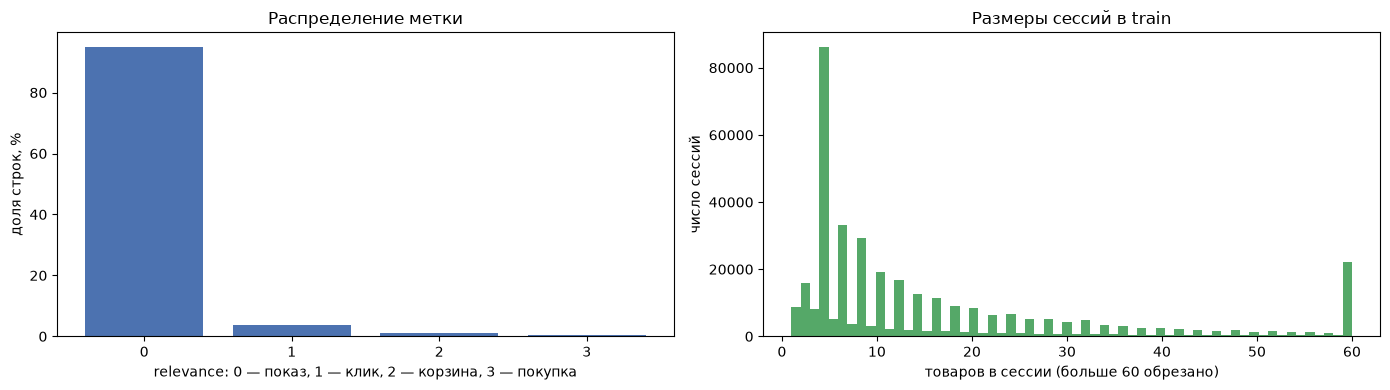

In [7]:
best_per_session = events.groupby('search_number')['relevance'].max()
print("сессий с кликом:  ", round(best_per_session.ge(1).mean() * 100, 1), "%")
print("сессий с корзиной:", round(best_per_session.ge(2).mean() * 100, 1), "%")
print("сессий с покупкой:", round(best_per_session.eq(3).mean() * 100, 1), "%")

sizes = events.groupby('search_number').size()
print("\nразмер группы:")
print(sizes.describe().round(1).to_string())
print("групп длиннее 20:", round(sizes.gt(20).mean() * 100, 1), "%")
print("групп из 5 и меньше:", round(sizes.le(5).mean() * 100, 1), "%")

label_share = events['relevance'].value_counts(normalize=True).sort_index() * 100

fig, (left_ax, right_ax) = plt.subplots(1, 2, figsize=(14, 4))

left_ax.bar(label_share.index.astype(str), label_share.values, color='#4c72b0')
left_ax.set_xlabel('relevance: 0 — показ, 1 — клик, 2 — корзина, 3 — покупка')
left_ax.set_ylabel('доля строк, %')
left_ax.set_title('Распределение метки')

right_ax.hist(sizes.clip(upper=60), bins=60, color='#55a868')
right_ax.set_xlabel('товаров в сессии (больше 60 обрезано)')
right_ax.set_ylabel('число сессий')
right_ax.set_title('Размеры сессий в train')

plt.tight_layout()
plt.show()

Метка редкая: 95% строк — нули, клик в 3.7%, покупка в 0.36%. При этом клик есть хотя бы в половине сессий. Значит NDCG@20 определён примерно на половине сессий: если все метки нули, идеальный DCG тоже ноль и метрика не определена. Это задаёт две вещи — маску при оценке и возможность избавиться от "некликабельных" сессий из обучения.


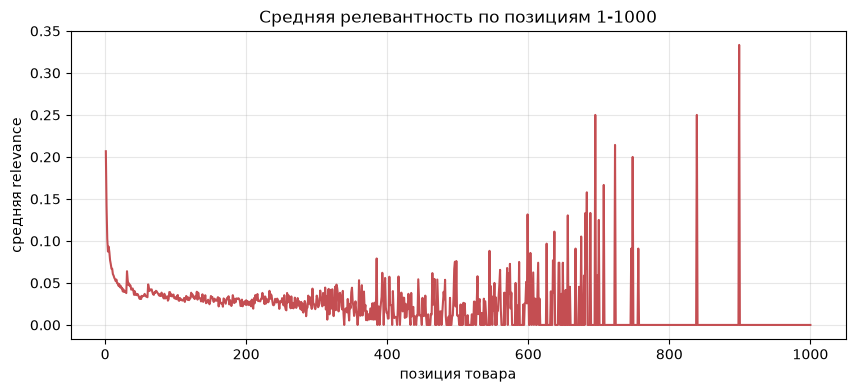

позиции   1-5   : средняя 0.1302, строк 1,550,101
позиции   6-10  : средняя 0.0750, строк 837,772
позиции  11-20  : средняя 0.0538, строк 979,762
позиции  21-50  : средняя 0.0425, строк 1,426,751
позиции  51-100 : средняя 0.0365, строк 939,903
позиции 100-200 : средняя 0.0307, строк 614,220
позиции 200-400 : средняя 0.0275, строк 204,767
позиции 400-700 : средняя 0.0189, строк 18,306
позиции 700-1000: средняя 0.0074, строк 2,039


In [8]:
mean_by_position = events.groupby('product_position')['relevance'].mean()

plt.figure(figsize=(10, 4))
mean_by_position.head(1000).plot(color='#c44e52')
plt.xlabel('позиция товара')
plt.ylabel('средняя relevance')
plt.title('Средняя релевантность по позициям 1-1000')
plt.grid(alpha=0.3)
plt.show()

for low, high in [(1, 5), (6, 10), (11, 20), (21, 50), (51, 100),
                  (100, 200), (200, 400), (400, 700), (700, 1000)]:
    chunk = events.loc[events['product_position'].between(low, high), 'relevance']
    print(f"позиции {low:>3}-{high:<4}: средняя {chunk.mean():.4f}, строк {len(chunk):,}")

Средняя релевантность падает с 0.130 в топ-5 до 0.030 после сотой позиции и 0.007 на 700–1000. Позиция несёт сильный сигнал, но он смешан с работой текущего ранжировщика: верхние товары кликают чаще не только потому, что они лучше.

Поэтому позиция остаётся в признаках — без неё модель потеряет много, — а перенос проверяется только на данных после даты отсечения. На случайном сплите такой признак выглядит лучше, чем он есть.

## 3. Признаки

Признаки делятся на три группы: карточка товара (тип, бренд, категория), контекст сессии (позиция, длина выдачи, параметры ответа) и совпадение запроса с карточкой. Сначала убираем дубли в справочнике, потом отбираем строки, потом считаем признаки.

In [9]:
print("карточек до:", catalog.shape)
catalog_unique = catalog.drop_duplicates(subset=['product_id']).copy()
print("карточек после:", catalog_unique.shape)
print("уникальных product_id:", catalog_unique['product_id'].nunique())

карточек до: (36673, 11)
карточек после: (36290, 11)
уникальных product_id: 36290


### 3.1. Какие строки идут в обучение

Валидация — последние два месяца train, деление по номеру сессии. Сплит по времени повторяет ситуацию теста: он идёт сразу после train, а не перемешан с ним. Сплит по строкам здесь не годится ещё и потому, что у части сессий дата встречается дважды — строки одной сессии не должны попасть в разные части.

В обучающей части остаются только сессии с кликами: в LambdaRank группа из одних нулей не даёт градиента, потому что любая перестановка внутри неё одинаково плоха. В остальных группах сохраняются все клики и до пяти негативов на клик — этого достаточно, чтобы модель видела разницу между «плохим» и «средним» показом, и втрое меньше строк, чем в полном объёме.

Размер сессии и процентиль позиции считаются до отбора строк: они должны описывать всю выдачу, которую видел пользователь, а не её урезанную часть.

In [10]:
def add_session_features(frame):
    frame['results_in_session'] = frame.groupby('search_number')['product_id'].transform('size').astype('int16')
    frame['position_percentile'] = (
        frame.groupby('search_number')['product_position'].rank(pct=True, method='min')
    ).astype('float32')
    return frame


all_queries = pd.Series(events['query'].astype(str).unique())
rows_total = len(events)

events = add_session_features(events)

session_day = events.groupby('search_number')['date'].min()
holdout_start = session_day.max() - pd.DateOffset(months=2)
holdout_sessions = session_day[session_day >= holdout_start].index
in_holdout = events['search_number'].isin(holdout_sessions)

clicked = (events['relevance'] > 0).astype('int8')
silent = (events['relevance'] == 0).astype('int8')
clicks_in_session = clicked.groupby(events['search_number']).transform('sum')
zeros_in_session = silent.groupby(events['search_number']).transform('sum')

negative_quota = np.maximum(5 * clicks_in_session, 5)
retention = np.minimum(1.0, negative_quota / zeros_in_session.clip(lower=1))
draw = np.random.default_rng(42).random(len(events))

keep = in_holdout.to_numpy() | (clicked.to_numpy() > 0) | (draw < retention.to_numpy())
train_rows = events.loc[keep].reset_index(drop=True)

print(f"строк было {rows_total:,}, осталось {len(train_rows):,} "
      f"({len(train_rows) / rows_total * 100:.0f}%)")
print(f"в валидации {int(in_holdout.sum()):,} строк")
print(f"окно валидации: {holdout_start.date()} … {session_day.max().date()}")

del events, clicked, silent, clicks_in_session, zeros_in_session, retention

строк было 6,559,360, осталось 3,136,658 (48%)
в валидации 1,061,983 строк
окно валидации: 2025-05-01 … 2025-07-01


Вероятность оставить конкретный негатив — это «сколько нужно добрать» делить на «сколько есть». В группе с одним кликом и сотней нулей останется пять нулей, в группе с двадцатью кликами — до сотни.

In [11]:
card_columns = ['product_id', 'type', 'brand', 'model', 'country',
                'category_name_1', 'category_name_2', 'category_name_3', 'category_name_4',
                'date_of_create']

rows_before_merge = len(train_rows)
train_rows = train_rows.merge(catalog_unique[card_columns], on='product_id', how='left')
print("строк до присоединения карточек:", rows_before_merge)
print("строк после:", len(train_rows), "| прирост:", len(train_rows) - rows_before_merge)


def add_card_features(frame):
    frame['date_of_create'] = pd.to_datetime(frame['date_of_create'])
    frame['price_byn'] = (frame['price'] / 100).astype('float32')
    frame['price_log'] = np.log1p(frame['price_byn']).astype('float32')
    frame['discount_share'] = (
        frame['price_discount'] / frame['price'].replace(0, np.nan)
    ).fillna(0).clip(0, 1).astype('float32')
    frame['query_chars'] = frame['query'].str.len().astype('int16')
    frame['days_since_listed'] = (frame['date'] - frame['date_of_create']).dt.days.astype('int32')
    return frame


train_rows = add_card_features(train_rows)

train_rows = train_rows.drop(columns=['user_number', 'product_id', 'price', 'price_byn',
                                      'date', 'date_of_create', 'country',
                                      'category_name_2', 'category_name_3', 'category_name_4'])

print(train_rows[['price_discount', 'price_log', 'discount_share', 'results_in_session',
                  'position_percentile', 'query_chars', 'days_since_listed']]
      .describe().round(2).to_string())
print("\nстолбцов осталось:", train_rows.shape[1])

строк до присоединения карточек: 3136658
строк после: 3136658 | прирост: 0
       price_discount   price_log  discount_share  results_in_session  position_percentile  query_chars  days_since_listed
count      3136658.00  3136658.00      3136658.00          3136658.00           3136658.00   3136658.00         3136658.00
mean         12309.36        5.44            0.09               35.40                 0.54        12.82             703.38
std          24262.40        2.27            0.13               40.41                 0.29         7.13             907.77
min              0.00        0.00            0.00                1.00                 0.00         1.00               1.00
25%              0.00        3.39            0.00                8.00                 0.28         8.00             200.00
50%            832.00        5.97            0.04               22.00                 0.52        11.00             413.00
75%          10000.00        7.55            0.15               

### 3.2. Совпадение запроса с карточкой

Запрос и карточка сравниваются по словам. Прежде чем сравнивать, запрос стоит починить: в логах есть строки, набранные в латинской раскладке (`cfvceyu` вместо «самсунг», `ntktajy` вместо «телефон»), и строки с опечатками (`телфон`, `капмулы`). Для текстовых признаков это критично: слово, которого нет ни в одной карточке, даёт ноль во всех метриках совпадения, хотя пользователь искал ровно этот товар.

Правило намеренно осторожное — лучше не исправить, чем испортить бренд:

- **раскладка.** Латинское слово переводится по позициям клавиш. Замена принимается, только если результат встречается в запросах не реже ста раз и самого латинского слова нет среди слов карточек. Без второго условия `iphone` превратился бы в `шзрщту` — такое слово в запросах тоже есть, его просто набирали в русской раскладке;
- **опечатки.** Слово, встречающееся не чаще двух раз, ищется среди частых слов на расстоянии одной правки (вставка, удаление, замена, перестановка) с той же первой буквой. Замена принимается, если кандидат единственный и минимум в десять раз частотнее.

Поиск идёт по индексу удалений: для каждого частого слова заранее сохраняются все варианты без одной буквы, и для редкого слова проверяются те же варианты. Это превращает перебор всего словаря в перебор по длине слова.

In [12]:
KEYBOARD = str.maketrans(
    "qwertyuiop[]asdfghjkl;'zxcvbnm,./`",
    "йцукенгшщзхъфывапролджэячсмитьбю.ё",
)


def is_one_edit(left, right):
    if left == right or abs(len(left) - len(right)) > 1:
        return False
    if len(left) > len(right):
        left, right = right, left
    position = 0
    while position < len(left) and left[position] == right[position]:
        position += 1
    if len(left) == len(right):
        if left[position + 1:] == right[position + 1:]:
            return True
        return (
            position + 1 < len(left)
            and left[position] == right[position + 1]
            and left[position + 1] == right[position]
            and left[position + 2:] == right[position + 2:]
        )
    return left[position:] == right[position + 1:]


def build_query_corrections(queries, protected_words, layout_min=100, typo_min=20, rare_max=2):
    word_freq = Counter()
    latin_freq = Counter()
    for query in queries:
        lowered = query.lower()
        word_freq.update(re.findall(r'[а-яё]+', lowered))
        latin_freq.update(re.findall(r'[a-z][a-z0-9]+', lowered))

    corrections = {}
    for token in latin_freq:
        if len(token) < 3 or token in protected_words:
            continue
        converted = token.translate(KEYBOARD)
        if re.search(r'[a-z]', converted):
            continue
        if word_freq[converted] >= layout_min:
            corrections[token] = converted
    layout_fixed = len(corrections)

    deletion_index = {}
    for word, count in word_freq.items():
        if count < typo_min or len(word) < 5:
            continue
        deletion_index.setdefault(word, set()).add(word)
        for position in range(len(word)):
            deletion_index.setdefault(word[:position] + word[position + 1:], set()).add(word)

    typo_fixed = 0
    for token, count in word_freq.items():
        if count > rare_max or len(token) < 5:
            continue
        candidates = set(deletion_index.get(token, ()))
        for position in range(len(token)):
            candidates |= deletion_index.get(token[:position] + token[position + 1:], set())
        candidates = [
            word for word in candidates
            if word[0] == token[0]
            and word_freq[word] >= max(typo_min, 10 * count)
            and is_one_edit(token, word)
        ]
        if len(candidates) == 1:
            corrections[token] = candidates[0]
            typo_fixed += 1

    print(f"слов в запросах: {len(word_freq):,} | раскладка: {layout_fixed:,} | опечатки: {typo_fixed:,}")
    return corrections


def correct_query(query, corrections):
    tokens = re.findall(r'[a-zа-яё0-9]+', query.lower())
    return ' '.join(corrections.get(token, token) for token in tokens)


protected_words = set()
for column in ['brand', 'model', 'type', 'country', 'category_name_1']:
    for value in catalog_unique[column].dropna().astype(str):
        protected_words.update(re.findall(r'[a-zа-яё0-9]+', value.lower()))

corrections = build_query_corrections(all_queries, protected_words)
del protected_words

changed_queries = {}
for query in all_queries:
    fixed = correct_query(query, corrections)
    if fixed != ' '.join(re.findall(r'[a-zа-яё0-9]+', query.lower())):
        changed_queries[query] = fixed

print(f"запросов: {len(all_queries):,} | изменилось: {len(changed_queries):,} "
      f"({len(changed_queries) / len(all_queries) * 100:.1f}%)")
for query, fixed in list(changed_queries.items())[:12]:
    print(f"  {query:<34} -> {fixed}")

слов в запросах: 22,820 | раскладка: 58 | опечатки: 2,448
запросов: 84,002 | изменилось: 3,001 (3.6%)
  тэлефон                            -> телефон
  кофе молотыц                       -> кофе молотый
  телеофон                           -> телефон
  ароматизатор вздуха                -> ароматизатор воздуха
  зеркальная моайка                  -> зеркальная мойка
  регулятор давления газового баллона novogas -> регулятор давления газового баллон novogas
  полог от комаров                   -> полов от комаров
  сялми 14                           -> сяоми 14
  часы смврт                         -> часы смарт
  спартфон                           -> смартфон
  айфмон                             -> айфон
  средства от таракаанов             -> средства от тараканов


In [13]:
match_key = ['query', 'model', 'brand', 'type']
match_features = ['word_overlap_model', 'model_terms_share', 'word_overlap_brand',
                  'brand_fully_matched', 'word_overlap_type', 'tfidf_similarity']


def clean_text(column):
    return (
        column.astype(str).str.lower()
        .str.replace('ё', 'е', regex=False)
        .str.replace(r'[^a-zа-я0-9\s]', ' ', regex=True)
        .str.replace(r'\s+', ' ', regex=True)
        .str.strip()
    )


combos = train_rows[match_key].drop_duplicates().reset_index(drop=True)
for column in match_key:
    combos[column + '_clean'] = clean_text(combos[column])
print("уникальных наборов (запрос, модель, бренд, тип):", f"{len(combos):,}")

counter = CountVectorizer(binary=True, token_pattern=r'(?u)\b\w+\b')
counter.fit(np.concatenate([combos[column + '_clean'].unique() for column in match_key]))
print("словарь:", f"{len(counter.vocabulary_):,}")

tfidf = TfidfVectorizer(token_pattern=r'(?u)\b\w+\b')
tfidf.fit(np.concatenate([combos['query_clean'].unique(), combos['model_clean'].unique()]))
del combos


def attach_match_scores(frame):
    combos = frame[match_key].drop_duplicates().reset_index(drop=True)

    raw_queries = combos['query'].astype(str).str.lower().unique()
    rewritten = {query: correct_query(query, corrections) for query in raw_queries}
    combos['query_fixed'] = combos['query'].astype(str).str.lower().map(rewritten)
    combos['query_clean'] = clean_text(combos['query_fixed'])
    for column in match_key[1:]:
        combos[column + '_clean'] = clean_text(combos[column])

    query_matrix = counter.transform(combos['query_clean'])
    query_terms = np.asarray(query_matrix.sum(axis=1)).ravel()

    for column in ['model', 'brand', 'type']:
        column_matrix = counter.transform(combos[column + '_clean'])
        shared = np.asarray(query_matrix.minimum(column_matrix).sum(axis=1)).ravel()
        column_terms = np.asarray(column_matrix.sum(axis=1)).ravel()
        union = query_terms + column_terms - shared
        combos['word_overlap_' + column] = np.where(union > 0, shared / np.maximum(union, 1), 0.0)
        if column == 'model':
            combos['model_terms_share'] = np.where(column_terms > 0,
                                                   shared / np.maximum(column_terms, 1), 0.0)
        if column == 'brand':
            combos['brand_fully_matched'] = ((column_terms > 0) & (shared == column_terms)).astype('int8')

    query_vectors = tfidf.transform(combos['query_clean'])
    model_vectors = tfidf.transform(combos['model_clean'])
    product = np.asarray(query_vectors.multiply(model_vectors).sum(axis=1)).ravel()
    query_size = np.sqrt(np.asarray(query_vectors.multiply(query_vectors).sum(axis=1)).ravel())
    model_size = np.sqrt(np.asarray(model_vectors.multiply(model_vectors).sum(axis=1)).ravel())
    combos['tfidf_similarity'] = np.where(
        (query_size > 0) & (model_size > 0),
        product / np.maximum(query_size * model_size, 1e-9),
        0.0,
    )
    del query_matrix, query_terms, column_matrix, shared, column_terms, union
    del query_vectors, model_vectors, product, query_size, model_size

    combos = combos.drop(columns=[column + '_clean' for column in match_key] + ['query_fixed'])
    lookup = pd.MultiIndex.from_frame(combos[match_key])
    positions = lookup.get_indexer(pd.MultiIndex.from_frame(frame[match_key]))
    if positions.min() < 0:
        raise ValueError("не все наборы ключей найдены при присоединении")

    for feature in match_features:
        frame[feature] = combos[feature].to_numpy(dtype='float32')[positions].astype('float32')

    print("пропусков в текстовых признаках:", int(frame[match_features].isna().sum().sum()))
    return frame


train_rows = attach_match_scores(train_rows)
print(train_rows[match_features].describe().round(3).to_string())

уникальных наборов (запрос, модель, бренд, тип): 1,004,311
словарь: 45,871
пропусков в текстовых признаках: 0
       word_overlap_model  model_terms_share  word_overlap_brand  brand_fully_matched  word_overlap_type  tfidf_similarity
count         3136658.000        3136658.000         3136658.000          3136658.000        3136658.000       3136658.000
mean                0.065              0.076               0.112                0.189              0.193             0.098
std                 0.114              0.128               0.266                0.391              0.321             0.166
min                 0.000              0.000               0.000                0.000              0.000             0.000
25%                 0.000              0.000               0.000                0.000              0.000             0.000
50%                 0.000              0.000               0.000                0.000              0.000             0.000
75%                 0.111    

Шесть признаков считаются по уникальным наборам «запрос — модель — бренд — тип»: их около миллиона против трёх миллионов строк, то есть работы втрое меньше. Считаются они на train и запоминаются вместе с векторизаторами, поэтому тест получает ровно те же величины.



## 4. Матрица признаков и схема оценки

строки одной сессии должны идти подряд. LambdaRank получает не номер группы, а размеры групп — он отрезает от таблицы куски указанной длины. Если строки перемешаны, группы сложатся из разных сессий, и модель будет учиться на случайных парах.

категориальные признаки кодируются одним словарём, построенным на train. Если кодировать каждую таблицу отдельно, один и тот же бренд получит в тесте другой номер; если кодировать по объединению, в train появятся коды, которых нет в данных. Поэтому словарь запоминается, а в тесте незнакомые значения получают `-1` — LightGBM считает отрицательные коды пропуском.


In [14]:
train_rows = train_rows.sort_values('search_number').reset_index(drop=True)
in_holdout = train_rows['search_number'].isin(holdout_sessions)

features = [
    'product_position', 'position_percentile', 'results_in_session', 'response_products',
    'browse_time', 'response_time', 'price_log', 'price_discount', 'discount_share',
    'query_chars', 'days_since_listed',
    'filters_applied', 'available', 'price_is_super', 'price_is_discounted',
    'word_overlap_model', 'model_terms_share', 'word_overlap_brand',
    'brand_fully_matched', 'word_overlap_type', 'tfidf_similarity',
]
cat_columns = ['device', 'type', 'brand', 'selected_category_id', 'category_name_1']

category_codes = {}
for column in cat_columns:
    values = sorted(train_rows[column].dropna().unique())
    category_codes[column] = values
    train_rows[column] = pd.Categorical(train_rows[column], categories=values).codes.astype('int32')

X_fit = train_rows.loc[~in_holdout, features + cat_columns].reset_index(drop=True)
X_holdout = train_rows.loc[in_holdout, features + cat_columns].reset_index(drop=True)
y_fit = train_rows.loc[~in_holdout, 'relevance'].to_numpy()
y_holdout = train_rows.loc[in_holdout, 'relevance'].to_numpy()

fit_ids = train_rows.loc[~in_holdout, 'search_number'].to_numpy()
holdout_ids = train_rows.loc[in_holdout, 'search_number'].to_numpy()
fit_sizes = train_rows.loc[~in_holdout].groupby('search_number', sort=False).size().to_numpy()
holdout_sizes = train_rows.loc[in_holdout].groupby('search_number', sort=False).size().to_numpy()

del train_rows

print(f"X_fit {X_fit.shape} | X_holdout {X_holdout.shape}")
print(f"групп: {len(fit_sizes):,} | {len(holdout_sizes):,}")
print("размеры групп согласованы:",
      fit_sizes.sum() == len(X_fit), holdout_sizes.sum() == len(X_holdout))
print("пересечение сессий:", len(set(fit_ids) & set(holdout_ids)))
print("пропуски:", int(X_fit.isna().sum().sum()), int(X_holdout.isna().sum().sum()))

print("\nдоли меток, train:", (pd.Series(y_fit).value_counts(normalize=True).sort_index() * 100).round(2).to_dict())
print("доли меток, valid:", (pd.Series(y_holdout).value_counts(normalize=True).sort_index() * 100).round(2).to_dict())
print("сессий в valid без кликов:", int((pd.Series(y_holdout).groupby(holdout_ids).max() == 0).sum()))
print(f"размер группы в valid: медиана {int(np.median(holdout_sizes))}, максимум {int(holdout_sizes.max())}")

X_fit (2074675, 26) | X_holdout (1061983, 26)
групп: 319,786 | 50,693
размеры групп согласованы: True True
пересечение сессий: 0
пропуски: 0 0

доли меток, train: {0: 86.55, 1: 9.96, 2: 2.52, 3: 0.98}
доли меток, valid: {0: 95.46, 1: 3.29, 2: 0.91, 3: 0.33}
сессий в valid без кликов: 24912
размер группы в valid: медиана 12, максимум 475


## 5. Модель

Используется `lambdarank`: он максимизирует число пар «релевантный товар выше нерелевантного», причём вес пары равен изменению NDCG при обмене. `label_gain = [0, 1, 3, 7]` — это `2**relevance - 1`, то есть покупка весит в семь раз больше клика, ровно как в метрике.
Гиперпараметры выбраны на валидации: `learning_rate 0.05`, `num_leaves 63`, `min_data_in_leaf 50`, `feature_fraction 0.7`, `bagging_fraction 0.7`. 
Обучается ансамбль из пяти моделей с разными сидами. 

In [15]:
session_best = pd.Series(y_holdout).groupby(holdout_ids).max()
scored_sessions = session_best[session_best > 0].index.to_numpy()
in_eval = np.isin(holdout_ids, scored_sessions)

eval_labels = y_holdout[in_eval]
eval_ids = holdout_ids[in_eval]
eval_sizes = pd.Series(eval_ids).groupby(eval_ids, sort=False).size().to_numpy()

print(f"строк в обучении: {len(X_fit):,} | групп: {len(fit_sizes):,} | "
      f"медиана группы: {int(np.median(fit_sizes))}")
print(f"кликов в обучении: {int((y_fit > 0).sum()):,}")
print(f"сессий в оценке: {len(eval_sizes):,}")

ranker_params = dict(
    objective='lambdarank',
    metric='ndcg',
    label_gain=[0, 1, 3, 7],
    lambdarank_truncation_level=20,
    learning_rate=0.05,
    num_leaves=63,
    min_child_samples=50,
    colsample_bytree=0.7,
    subsample=0.7,
    subsample_freq=1,
    n_estimators=3000,
    n_jobs=4,
    verbosity=-1,
)

ensemble = []
for seed in [42, 2024, 777, 7, 123]:
    ranker = lgb.LGBMRanker(
        **ranker_params,
        random_state=seed,
        bagging_seed=seed,
        feature_fraction_seed=seed,
    )
    ranker.fit(
        X_fit, y_fit,
        group=fit_sizes,
        eval_set=[(X_holdout[in_eval], eval_labels)],
        eval_group=[eval_sizes],
        eval_at=[20],
        categorical_feature=cat_columns,
        callbacks=[lgb.early_stopping(100), lgb.log_evaluation(200)],
    )
    ensemble.append(ranker)
    score = ranker.booster_.best_score['valid_0']['ndcg@20']
    print(f"сид {seed}: {ranker.best_iteration_} итераций, ndcg@20 {score:.5f}")

строк в обучении: 2,074,675 | групп: 319,786 | медиана группы: 5
кликов в обучении: 279,072
сессий в оценке: 25,781
Training until validation scores don't improve for 100 rounds
[200]	valid_0's ndcg@20: 0.553316
[400]	valid_0's ndcg@20: 0.555619
Early stopping, best iteration is:
[419]	valid_0's ndcg@20: 0.555898
сид 42: 419 итераций, ndcg@20 0.55590
Training until validation scores don't improve for 100 rounds
[200]	valid_0's ndcg@20: 0.553362
[400]	valid_0's ndcg@20: 0.555441
[600]	valid_0's ndcg@20: 0.556635
Early stopping, best iteration is:
[625]	valid_0's ndcg@20: 0.556893
сид 2024: 625 итераций, ndcg@20 0.55689
Training until validation scores don't improve for 100 rounds
[200]	valid_0's ndcg@20: 0.552874
[400]	valid_0's ndcg@20: 0.554758
[600]	valid_0's ndcg@20: 0.555623
Early stopping, best iteration is:
[582]	valid_0's ndcg@20: 0.556101
сид 777: 582 итераций, ndcg@20 0.55610
Training until validation scores don't improve for 100 rounds
[200]	valid_0's ndcg@20: 0.553151
[400]	

## Что означают две строки в выводе

**`ансамбль(full_model)`** — метрика модели. Скор каждого товара — это среднее предсказание пяти моделей, обученных с разными сидами (42, 2024, 777, 7, 123). Усредняются именно скоры, а не метрики: NDCG считается один раз, уже по усреднённому скору, поэтому в строке одно число, а не среднее пяти NDCG.


полная сессия:
  ансамбль    0.5591
  сессий      25,722

двадцать кандидатов:
  ансамбль    0.6303
  сессий      25,722

важность признаков:
            feature          gain    share
              brand 260078.267917 0.262217
position_percentile 157274.847790 0.158568
   product_position 117730.765835 0.118699
               type  67535.662733 0.068091
 results_in_session  49399.332620 0.049806
          price_log  47572.611343 0.047964
   tfidf_similarity  36884.126212 0.037187
  response_products  36519.201616 0.036820
  days_since_listed  36199.229843 0.036497
    filters_applied  31727.852890 0.031989
        browse_time  21825.742528 0.022005
     discount_share  20356.381632 0.020524
      response_time  19698.553053 0.019861
        query_chars  16732.238647 0.016870
 word_overlap_model  11604.175835 0.011700


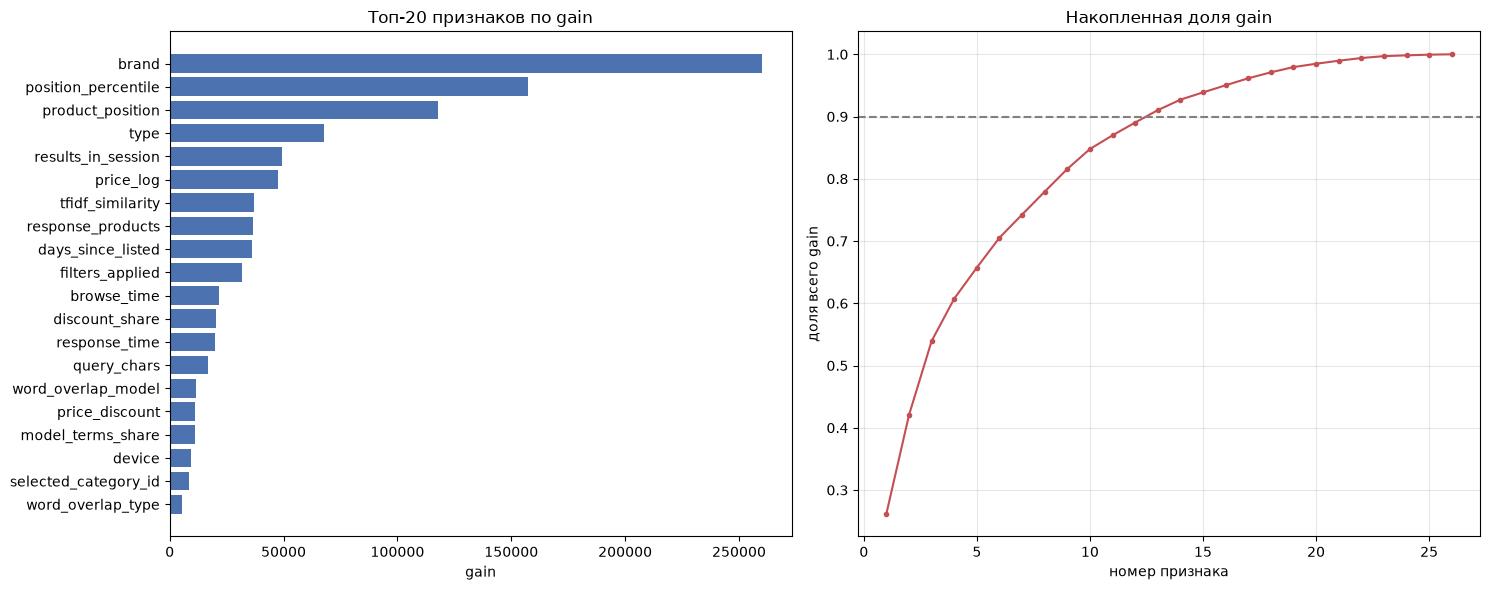


топ-5 признаков дают 65.7% всего gain


In [16]:
ensemble_scores = np.mean([model.predict(X_holdout[in_eval]) for model in ensemble], axis=0)


def ndcg_per_session(labels, scores, sizes):
    cuts = np.cumsum(sizes)[:-1]
    values = [
        ndcg_score([group_labels], [group_scores], k=20)
        for group_labels, group_scores in zip(np.split(labels, cuts), np.split(scores, cuts))
        if len(group_labels) > 1
    ]
    return float(np.mean(values)), len(values)


full_model, full_sessions = ndcg_per_session(eval_labels, ensemble_scores, eval_sizes)

print("полная сессия:")
print(f"  ансамбль    {full_model:.4f}")
print(f"  сессий      {full_sessions:,}")

selector = pd.DataFrame({'group': eval_ids, 'label': eval_labels})
selector['is_click'] = (eval_labels > 0).astype(int)
selector['tie_break'] = np.random.default_rng(42).random(len(selector))
ordered = selector.sort_values(['group', 'is_click', 'tie_break'], ascending=[True, False, True])
ordered['rank_in_group'] = ordered.groupby('group', sort=False).cumcount()
chosen = ordered.index[ordered['rank_in_group'] < 20].to_numpy()

top20_labels = eval_labels[chosen]
top20_sizes = pd.Series(eval_ids[chosen]).groupby(eval_ids[chosen], sort=False).size().to_numpy()

top20_model, top20_sessions = ndcg_per_session(top20_labels, ensemble_scores[chosen], top20_sizes)

print("\nдвадцать кандидатов:")
print(f"  ансамбль    {top20_model:.4f}")
print(f"  сессий      {top20_sessions:,}")

gains = np.mean([model.booster_.feature_importance(importance_type='gain') for model in ensemble], axis=0)
importance = pd.DataFrame({
    'feature': ensemble[0].booster_.feature_name(),
    'gain': gains,
}).sort_values('gain', ascending=False)
importance['share'] = importance['gain'] / importance['gain'].sum()

print("\nважность признаков:")
print(importance.head(15).to_string(index=False))

fig, (left_ax, right_ax) = plt.subplots(1, 2, figsize=(15, 6))

top_features = importance.head(20).iloc[::-1]
left_ax.barh(top_features['feature'], top_features['gain'], color='#4c72b0')
left_ax.set_title('Топ-20 признаков по gain')
left_ax.set_xlabel('gain')

right_ax.plot(np.arange(1, len(importance) + 1), importance['share'].cumsum().to_numpy(),
              marker='o', markersize=3, color='#c44e52')
right_ax.axhline(0.9, color='grey', linestyle='--')
right_ax.set_title('Накопленная доля gain')
right_ax.set_xlabel('номер признака')
right_ax.set_ylabel('доля всего gain')
right_ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nтоп-5 признаков дают {importance['share'].head(5).sum() * 100:.1f}% всего gain")

## 6. Результаты

| Модель | Полная сессия | 20 кандидатов |
|---|---|---|
| **ансамбль LambdaRank** | **0.5591** | **0.6303** |
| сортировка по позиции (замер при разработке) | 0.5004 | 0.5786 |



## 7. Предсказание для теста

Тест проходит ту же подготовку, что train: те же функции признаков, те же обученные векторизаторы, тот же словарь исправлений и тот же словарь категорий.

Скоры пяти моделей усредняются. Абсолютная величина скора для NDCG не важна — учитывается только порядок внутри сессии.

In [17]:
del X_holdout, X_fit
gc.collect()

test = add_session_features(test)
test = test.merge(catalog_unique[card_columns], on='product_id', how='left')
print("строк в тесте:", len(test), "| пропусков:", int(test.isna().sum().sum()))

test = add_card_features(test)
test = attach_match_scores(test)

for column in cat_columns:
    test[column] = pd.Categorical(test[column], categories=category_codes[column]).codes.astype('int32')

X_test = test[features + cat_columns]
print("X_test:", X_test.shape, "| пропуски:", int(X_test.isna().sum().sum()))

test_scores = np.mean([model.predict(X_test) for model in ensemble], axis=0)

submission = pd.DataFrame({
    'session_product_id': test['session_product_id'],
    'relevance': test_scores.astype(float),
})
submission.to_csv('submission.csv', index=False)

print("\nsubmission.csv:", submission.shape)
print(submission.head())

строк в тесте: 252720 | пропусков: 0
пропусков в текстовых признаках: 0
X_test: (252720, 26) | пропуски: 0

submission.csv: (252720, 2)
  session_product_id  relevance
0         10_8080243   0.252481
1         10_8826131  -0.620898
2         10_7850512  -1.159145
3         10_5897964  -0.421616
4         10_6915061  -1.434383


## Альтернатива
Я бы попробовал вместо бустинга применить нейросети, как используют большинство рекомендательных систем сейчас. Тот же WB со своим WildBERT, так же посмотреть модели которые обрабатывает запросы пользователя и тд. 